In [1]:
# Google Colabを使っている場合には、ドライブのマウントを行います
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
cd /content/drive/MyDrive/kaggle/SolarFilament

/content/drive/MyDrive/kaggle/SolarFilament


In [3]:
!pip -q install pycocotools ipywidgets opencv-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 15.5 MB/s eta 0:00:00


In [4]:
!pip install pycocotools

In [5]:
!pip -q install ipympl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.0/519.0 kB 2.3 MB/s eta 0:00:00


In [6]:
import os
import json
import glob

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from pycocotools.coco import COCO
from pycocotools import mask as maskUtils

In [7]:
ls

filament_img/            soloar_filament_2_bilateral.ipynb  train/
soloar_filament_1.ipynb  test/


In [8]:
# =========================
# パス設定
# =========================

IMAGE_DIR = (
    "/content/drive/MyDrive/kaggle/SolarFilament/train/"
    "train_images"
)

JSON_PATH = (
    "/content/drive/MyDrive/kaggle/SolarFilament/train/"
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

assert os.path.isdir(IMAGE_DIR), f"画像フォルダがありません: {IMAGE_DIR}"
assert os.path.isfile(JSON_PATH), f"JSONがありません: {JSON_PATH}"

print("画像フォルダ:", IMAGE_DIR)
print("JSONファイル:", JSON_PATH)

画像フォルダ: /content/drive/MyDrive/kaggle/SolarFilament/train/train_images
JSONファイル: /content/drive/MyDrive/kaggle/SolarFilament/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json


## COCOデータを読み込む

In [9]:
# =========================
# COCOアノテーションを読み込む
# =========================

coco = COCO(JSON_PATH)

print("画像数:", len(coco.imgs))
print("アノテーション数:", len(coco.anns))
print("カテゴリ数:", len(coco.cats))

print("\nカテゴリ:")
for category_id, category in coco.cats.items():
    print(category_id, category)

loading annotations into memory...
Done (t=2.62s)
creating index...
index created!
画像数: 1154
アノテーション数: 8199
カテゴリ数: 4

カテゴリ:
1 {'supercategory': 'filament', 'id': 1, 'name': 'Left'}
2 {'supercategory': 'filament', 'id': 2, 'name': 'Right'}
3 {'supercategory': 'filament', 'id': 3, 'name': 'Unidentifiable'}
4 {'supercategory': 'filament', 'id': 4, 'name': 'Ambiguous'}


In [10]:
import json
from collections import Counter

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

print("トップレベルのキー:", list(coco.keys()))
print("画像レコード数:", len(coco.get("images", [])))
print("アノテーション数:", len(coco.get("annotations", [])))
print("カテゴリ:", coco.get("categories", []))

print("\n画像レコードの例:")
print(coco["images"][0])

print("\nアノテーションの例:")
print(coco["annotations"][0])

segmentation_types = Counter(
    type(a.get("segmentation")).__name__
    for a in coco.get("annotations", [])
)
print("\nsegmentationの型:", segmentation_types)

if coco.get("annotations"):
    seg = coco["annotations"][0].get("segmentation")
    print("segmentationの内容の例:", str(seg)[:500])

トップレベルのキー: ['info', 'licenses', 'categories', 'images', 'annotations']
画像レコード数: 1154
アノテーション数: 8199
カテゴリ: [{'supercategory': 'filament', 'id': 1, 'name': 'Left'}, {'supercategory': 'filament', 'id': 2, 'name': 'Right'}, {'supercategory': 'filament', 'id': 3, 'name': 'Unidentifiable'}, {'supercategory': 'filament', 'id': 4, 'name': 'Ambiguous'}]

画像レコードの例:
{'license': 1, 'file_name': '20140609195854Bh.jpeg', 'url': 'https://gong2.nso.edu/HA/hag/201406/20140609/20140609195854Bh.jpg', 'height': 2048, 'width': 2048, 'date_captured': '2014-06-09 19:58:54', 'id': '040301-20140609195854Bh'}

アノテーションの例:
{'segmentation': [[480.9382, 850.955, 480.307, 852.0535, 478.2989, 852.451, 476.1202, 851.3087, 471.8813, 845.6188, 469.2107, 844.1978, 460.0, 845.0, 459.0, 844.0, 455.9884, 843.2471, 452.2964, 839.9584, 450.6544, 839.7575, 449.7991, 838.6671, 450.223, 837.6258, 447.5581, 834.6278, 445.4449, 829.1312, 442.9577, 825.6077, 441.8277, 824.4777, 438.6437, 823.5973, 439.0, 821.0, 436.0, 818.0, 435.15

## 画像を選び、セグメンテーションを復元する

画像ファイル数: 707
JSONに登録された画像名の数: 707
画像ファイルの例: ['20110109104734Ch.jpeg', '20110114105034Ch.jpeg', '20110119082634Lh.jpeg', '20110123174914Mh.jpeg', '20110128174814Mh.jpeg']
画像: 20110109104734Ch.jpeg
画像サイズ: (2048, 2048)
マスク画素数: 5075
対象アノテーション数: 6


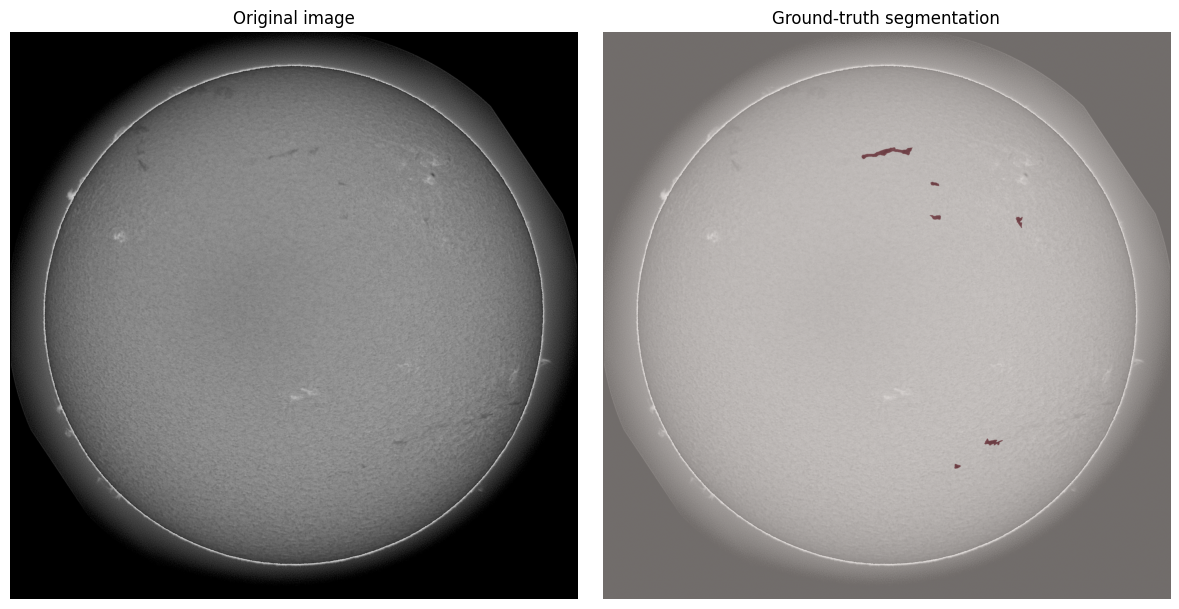

In [11]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pycocotools import mask as mask_utils

# ファイル名から画像レコードを検索できるようにする
images_by_name = {}

for image_info in coco["images"]:
    filename = os.path.basename(image_info["file_name"])
    images_by_name.setdefault(filename, []).append(image_info)

# 画像ファイル一覧
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("画像ファイル数:", len(image_files))
print("JSONに登録された画像名の数:", len(images_by_name))
print("画像ファイルの例:", image_files[:5])


def annotation_to_mask(annotation, height=2048, width=2048):
    """
    COCO形式のアノテーションを2次元の二値マスクに変換する。
    ポリゴン形式とRLE形式に対応する。
    """
    segmentation = annotation.get("segmentation")

    if segmentation is None:
        return np.zeros((height, width), dtype=np.uint8)

    # ポリゴン形式
    if isinstance(segmentation, list):
        if len(segmentation) == 0:
            return np.zeros((height, width), dtype=np.uint8)

        rles = mask_utils.frPyObjects(
            segmentation, height, width
        )
        rle = mask_utils.merge(rles)

    # RLE形式
    elif isinstance(segmentation, dict):
        rle = segmentation

        # 圧縮されていないRLEの場合は変換
        if isinstance(rle.get("counts"), list):
            rle = mask_utils.frPyObjects(
                rle, height, width
            )

    else:
        raise ValueError(
            f"未対応のsegmentation形式: {type(segmentation)}"
        )

    decoded = mask_utils.decode(rle)

    # 複数マスクが返された場合は統合する
    if decoded.ndim == 3:
        decoded = np.any(decoded, axis=2)

    return decoded.astype(np.uint8)


def load_image_and_mask(filename):
    image_path = os.path.join(IMAGE_DIR, filename)

    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(image_path)

    h, w = image.shape
    combined_mask = np.zeros((h, w), dtype=np.uint8)

    # 同じファイル名に対応するすべての画像レコードを取得
    image_records = images_by_name.get(filename, [])

    if not image_records:
        print("警告: JSONにこの画像のレコードがありません:", filename)

    image_ids = {str(record["id"]) for record in image_records}

    annotations = [
        ann for ann in coco["annotations"]
        if str(ann["image_id"]) in image_ids
    ]

    for ann in annotations:
        current_mask = annotation_to_mask(
            ann, height=h, width=w
        )
        combined_mask |= current_mask

    return image, combined_mask, annotations


# まず1枚読み込んで確認
test_filename = image_files[0]
test_image, test_mask, test_annotations = load_image_and_mask(
    test_filename
)

print("画像:", test_filename)
print("画像サイズ:", test_image.shape)
print("マスク画素数:", int(test_mask.sum()))
print("対象アノテーション数:", len(test_annotations))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(test_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(test_image, cmap="gray", vmin=0, vmax=255)
axes[1].imshow(test_mask, cmap="Reds", alpha=0.45, vmin=0, vmax=1)
axes[1].set_title("Ground-truth segmentation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

マウス操作に対応した画像ビューア  
ここがメインのプログラムです。  
- 元画像を左クリック：元画像（200x200）→　拡大画像表示（400x400）  
- 拡大画像：右クリックー＞ヒストグラム表示、左クリックー＞画素値  

In [12]:
import os
import io
import base64
import uuid
import numpy as np
from PIL import Image
from IPython.display import display, HTML


def png_data_url(array, mode):
    """NumPy配列をPNGのData URLに変換する"""
    buffer = io.BytesIO()
    Image.fromarray(array, mode=mode).save(buffer, format="PNG")
    encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
    return "data:image/png;base64," + encoded


def show_filament_canvas(filename):
    # ----------------------------------------
    # 1. 元画像と正解マスクを読み込む
    # ----------------------------------------
    image, mask, annotations = load_image_and_mask(filename)

    height, width = image.shape

    # 元画像をPNG化
    image_url = png_data_url(image, "L")

    # 正解マスク：フィラメント部分を半透明の赤色にする
    overlay = np.zeros((height, width, 4), dtype=np.uint8)
    overlay[mask > 0] = [255, 0, 0, 110]
    mask_url = png_data_url(overlay, "RGBA")

    uid = "solar_" + uuid.uuid4().hex[:10]

    # ----------------------------------------
    # 2. HTML / JavaScript
    # ----------------------------------------
    html = r"""
    <div id="ROOT" style="font-family:Arial,sans-serif; color:#222;">

      <div style="font-weight:bold; margin-bottom:8px;">
        ファイル：FILENAME
      </div>

      <div style="font-size:13px; margin-bottom:8px;">
        元画像：右クリックで拡大領域を選択。
        拡大画像：左クリックで画素値、右クリックでヒストグラム。
      </div>

      <div style="display:flex; flex-wrap:wrap; gap:20px;
                  align-items:flex-start;">

        <div>
          <div style="font-weight:bold; margin-bottom:5px;">
            元画像 2048 × 2048
          </div>

          <canvas id="MAIN"
            style="width:min(650px,95vw); height:auto;
                   border:1px solid #888; cursor:crosshair;
                   display:block;">
          </canvas>
        </div>

        <div style="max-width:100%;">
          <div style="font-weight:bold; margin-bottom:5px;">
            拡大画像 400 × 400（2倍）
          </div>

          <canvas id="ZOOM"
            width="400" height="400"
            style="width:400px; max-width:95vw; height:auto;
                   border:1px solid #888; cursor:crosshair;
                   display:block;">
          </canvas>
        </div>
      </div>

      <div id="STATUS"
        style="margin-top:12px; padding:10px;
               background:#f1f3f4; color:#111;
               line-height:1.8; white-space:normal;">
        画像の読み込み中です。
      </div>

      <div style="margin-top:16px;">
        <div style="font-weight:bold;">
          フィラメントと背景の画素値ヒストグラム
        </div>
        <div id="HISTINFO" style="font-size:13px; margin:5px 0;">
          拡大画像を右クリックすると表示します。
        </div>

        <canvas id="HIST"
          width="800" height="330"
          style="width:min(800px,98vw); height:auto;
                 border:1px solid #ccc; display:block;">
        </canvas>
      </div>
    </div>

    <script>
    (() => {
      const root = document.getElementById("ROOT");
      const main = document.getElementById("MAIN");
      const zoom = document.getElementById("ZOOM");
      const hist = document.getElementById("HIST");
      const status = document.getElementById("STATUS");
      const histInfo = document.getElementById("HISTINFO");

      const ctx = main.getContext("2d", {willReadFrequently:true});
      const zctx = zoom.getContext("2d", {willReadFrequently:true});
      const hctx = hist.getContext("2d");

      const image = new Image();
      const maskImage = new Image();

      // 元画像とマスクの画素値を独立して取得するCanvas
      const sourceCanvas = document.createElement("canvas");
      const sourceCtx = sourceCanvas.getContext(
        "2d", {willReadFrequently:true}
      );

      const maskCanvas = document.createElement("canvas");
      const maskCtx = maskCanvas.getContext(
        "2d", {willReadFrequently:true}
      );

      let ready = false;
      let cropX = 0;
      let cropY = 0;
      let selectedX = 0;
      let selectedY = 0;

      // ------------------------------------
      // 画像表示を初期化
      // ------------------------------------
      function initialize() {
        const w = image.naturalWidth;
        const h = image.naturalHeight;

        main.width = w;
        main.height = h;

        sourceCanvas.width = w;
        sourceCanvas.height = h;
        sourceCtx.drawImage(image, 0, 0);

        maskCanvas.width = w;
        maskCanvas.height = h;
        maskCtx.drawImage(maskImage, 0, 0);

        // 元画像と正解マスクを重ねる
        ctx.clearRect(0, 0, w, h);
        ctx.drawImage(image, 0, 0);
        ctx.drawImage(maskImage, 0, 0);

        // 初期拡大画像：画像中央
        cropX = Math.max(0, Math.floor((w - 200) / 2));
        cropY = Math.max(0, Math.floor((h - 200) / 2));

        drawZoom();

        ready = true;

        status.textContent =
          "読み込み完了。元画像を右クリックして拡大領域を選択してください。";
      }


      function drawZoom() {
          // 拡大画像：元画像の画素値をそのまま表示
          zctx.clearRect(0, 0, 400, 400);

          zctx.drawImage(
              sourceCanvas,
              cropX, cropY, 200, 200,
              0, 0, 400, 400
          );

          // 正解マスクは拡大画像に重ねない

          // 元画像を再描画
          ctx.clearRect(0, 0, main.width, main.height);
          ctx.drawImage(image, 0, 0);
          ctx.drawImage(maskImage, 0, 0);

          // 拡大範囲を青い四角で表示
          ctx.strokeStyle = "#00A0FF";
          ctx.lineWidth = Math.max(
              2, main.width / 2048 * 3
          );

          ctx.strokeRect(
              cropX, cropY, 200, 200
          );
      }

      // ------------------------------------
      // マウス位置を元画像の画素座標に変換
      // ------------------------------------
      function canvasPoint(event, canvas) {
        const rect = canvas.getBoundingClientRect();

        return {
          x: Math.max(0, Math.min(
            canvas.width - 1,
            Math.floor(
              (event.clientX - rect.left) *
              canvas.width / rect.width
            )
          )),
          y: Math.max(0, Math.min(
            canvas.height - 1,
            Math.floor(
              (event.clientY - rect.top) *
              canvas.height / rect.height
            )
          ))
        };
      }

      function pixelInfo(x, y) {
        const p = sourceCtx.getImageData(x, y, 1, 1).data;
        const m = maskCtx.getImageData(x, y, 1, 1).data;

        return {
          value: p[0],
          filament: m[3] > 0
        };
      }

      // ------------------------------------
      // 端を考慮して切り出し位置を調整
      // ------------------------------------
      function clampCrop(x, y, size) {
        const w = sourceCanvas.width;
        const h = sourceCanvas.height;

        return {
          x: Math.max(0, Math.min(
            Math.round(x - size / 2), w - size
          )),
          y: Math.max(0, Math.min(
            Math.round(y - size / 2), h - size
          ))
        };
      }

      // ------------------------------------
      // 元画像を右クリック → 拡大画像更新
      // ------------------------------------
      main.addEventListener("contextmenu", e => {
        e.preventDefault();
      });

      main.addEventListener("mousedown", e => {
        if (!ready || e.button !== 2) return;

        e.preventDefault();

        const p = canvasPoint(e, main);

        const crop = clampCrop(p.x, p.y, 200);
        cropX = crop.x;
        cropY = crop.y;

        selectedX = p.x;
        selectedY = p.y;

        drawZoom();

        const info = pixelInfo(p.x, p.y);

        status.innerHTML =
          "<b>拡大領域を選択しました</b><br>" +
          "元画像座標：x=" + p.x + ", y=" + p.y + "<br>" +
          "切り出し範囲：x=" + cropX + "～" +
          (cropX + 199) + ", y=" + cropY + "～" +
          (cropY + 199) + "<br>" +
          "選択点の画素値：" + info.value + "<br>" +
          "正解マスク：" +
          (info.filament ? "フィラメント" : "背景");

        histInfo.textContent =
          "拡大画像を右クリックして比較領域を選択してください。";
      });

      // ------------------------------------
      // 拡大画像を左クリック → 座標と画素値
      // ------------------------------------
      zoom.addEventListener("contextmenu", e => {
        e.preventDefault();
      });

      zoom.addEventListener("mousedown", e => {
        if (!ready) return;

        e.preventDefault();

        const p = canvasPoint(e, zoom);

        // 400×400上の位置を元画像座標へ戻す
        const x = cropX + Math.floor(p.x / 2);
        const y = cropY + Math.floor(p.y / 2);

        const info = pixelInfo(x, y);

        if (e.button === 0) {
          status.innerHTML =
            "<b>拡大画像の左クリック</b><br>" +
            "拡大画像座標：x=" + p.x + ", y=" + p.y + "<br>" +
            "元画像座標：x=" + x + ", y=" + y + "<br>" +
            "元画像の画素値：" + info.value + "<br>" +
            "正解マスク：" +
            (info.filament ? "フィラメント" : "背景");
        }

        // --------------------------------
        // 拡大画像を右クリック → ヒストグラム
        // --------------------------------
        if (e.button === 2) {
          const region = clampCrop(x, y, 100);

          drawHistogram(region.x, region.y, 100);

          status.innerHTML =
            "<b>ヒストグラム比較領域</b><br>" +
            "中心点：x=" + x + ", y=" + y + "<br>" +
            "比較範囲：x=" + region.x + "～" +
            (region.x + 99) + ", y=" + region.y + "～" +
            (region.y + 99);
        }
      });

      // ------------------------------------
      // 100×100領域の2種類のヒストグラム
      // ------------------------------------
      function drawHistogram(x0, y0, size) {
        const imageData = sourceCtx.getImageData(
          x0, y0, size, size
        ).data;

        const maskData = maskCtx.getImageData(
          x0, y0, size, size
        ).data;

        const filamentHist = new Array(256).fill(0);
        const backgroundHist = new Array(256).fill(0);

        let filamentCount = 0;
        let backgroundCount = 0;

        for (let i = 0; i < imageData.length; i += 4) {
          const value = imageData[i];
          const isFilament = maskData[i + 3] > 0;

          if (isFilament) {
            filamentHist[value]++;
            filamentCount++;
          } else {
            backgroundHist[value]++;
            backgroundCount++;
          }
        }

        renderHistogram(
          filamentHist, backgroundHist,
          filamentCount, backgroundCount
        );

        histInfo.textContent =
          "赤：フィラメント（" + filamentCount +
          "画素）　青：背景（" + backgroundCount +
          "画素）　合計：" +
          (filamentCount + backgroundCount) + "画素";
      }

      // ------------------------------------
      // ヒストグラムをCanvasに描画
      // ------------------------------------
      function renderHistogram(fHist, bHist, nF, nB) {
        const W = hist.width;
        const H = hist.height;

        hctx.clearRect(0, 0, W, H);
        hctx.fillStyle = "#ffffff";
        hctx.fillRect(0, 0, W, H);

        const left = 55;
        const right = 20;
        const top = 42;
        const bottom = 45;

        const plotW = W - left - right;
        const plotH = H - top - bottom;

        const maxCount = Math.max(
          1, ...fHist, ...bHist
        );

        // 軸
        hctx.strokeStyle = "#333";
        hctx.lineWidth = 1;
        hctx.beginPath();
        hctx.moveTo(left, top);
        hctx.lineTo(left, top + plotH);
        hctx.lineTo(left + plotW, top + plotH);
        hctx.stroke();

        // 横方向の目盛り
        hctx.font = "12px Arial";
        hctx.fillStyle = "#222";
        hctx.textAlign = "center";

        [0, 64, 128, 192, 255].forEach(v => {
          const px = left + (v / 255) * plotW;

          hctx.strokeStyle = "#dddddd";
          hctx.beginPath();
          hctx.moveTo(px, top);
          hctx.lineTo(px, top + plotH);
          hctx.stroke();

          hctx.fillStyle = "#222";
          hctx.fillText(
            String(v), px, top + plotH + 18
          );
        });

        // 縦方向の目盛り
        hctx.textAlign = "right";

        for (let k = 0; k <= 4; k++) {
          const count = Math.round(maxCount * k / 4);
          const py = top + plotH - plotH * k / 4;

          hctx.strokeStyle = "#eeeeee";
          hctx.beginPath();
          hctx.moveTo(left, py);
          hctx.lineTo(left + plotW, py);
          hctx.stroke();

          hctx.fillStyle = "#222";
          hctx.fillText(String(count), left - 7, py + 4);
        }

        // タイトル
        hctx.textAlign = "center";
        hctx.font = "bold 14px Arial";
        hctx.fillStyle = "#222";
        hctx.fillText(
          "Pixel intensity histogram (0-255)",
          W / 2, 20
        );

        // 棒グラフ：各画素値に2本ずつ描く
        const binW = plotW / 256;
        const barW = Math.max(1, binW * 0.46);

        for (let v = 0; v < 256; v++) {
          const baseX = left + v * binW;

          const hf = (fHist[v] / maxCount) * plotH;
          const hb = (bHist[v] / maxCount) * plotH;

          hctx.fillStyle = "#e53935";
          hctx.fillRect(
            baseX, top + plotH - hf,
            barW, hf
          );

          hctx.fillStyle = "#2878d0";
          hctx.fillRect(
            baseX + barW, top + plotH - hb,
            barW, hb
          );
        }

        // 凡例
        hctx.fillStyle = "#e53935";
        hctx.fillRect(W - 250, 29, 12, 12);
        hctx.fillStyle = "#222";
        hctx.textAlign = "left";
        hctx.font = "12px Arial";
        hctx.fillText("Filament", W - 233, 40);

        hctx.fillStyle = "#2878d0";
        hctx.fillRect(W - 145, 29, 12, 12);
        hctx.fillStyle = "#222";
        hctx.fillText("Background", W - 128, 40);

        // 軸ラベル
        hctx.textAlign = "center";
        hctx.fillText(
          "Pixel intensity", left + plotW / 2, H - 5
        );

        hctx.save();
        hctx.translate(14, top + plotH / 2);
        hctx.rotate(-Math.PI / 2);
        hctx.textAlign = "center";
        hctx.fillText("Pixel count", 0, 0);
        hctx.restore();
      }

      // ------------------------------------
      // 画像読み込み
      // ------------------------------------
      let loaded = 0;

      function onLoaded() {
        loaded++;
        if (loaded === 2) initialize();
      }

      image.onload = onLoaded;
      maskImage.onload = onLoaded;

      image.onerror = () => {
        status.textContent = "元画像を読み込めませんでした。";
      };

      maskImage.onerror = () => {
        status.textContent = "正解マスクを読み込めませんでした。";
      };

      image.src = "IMAGE_URL";
      maskImage.src = "MASK_URL";
    })();
    </script>
    """

    html = (
        html.replace("ROOT", uid + "_root")
            .replace("MAIN", uid + "_main")
            .replace("ZOOM", uid + "_zoom")
            .replace("STATUS", uid + "_status")
            .replace("HISTINFO", uid + "_histinfo")
            .replace("HIST", uid + "_hist")
            .replace("FILENAME", filename)
            .replace("IMAGE_URL", image_url)
            .replace("MASK_URL", mask_url)
    )

    display(HTML(html))

/tmp/ipykernel_1636/2847904506.py:13: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(array, mode=mode).save(buffer, format="PNG")



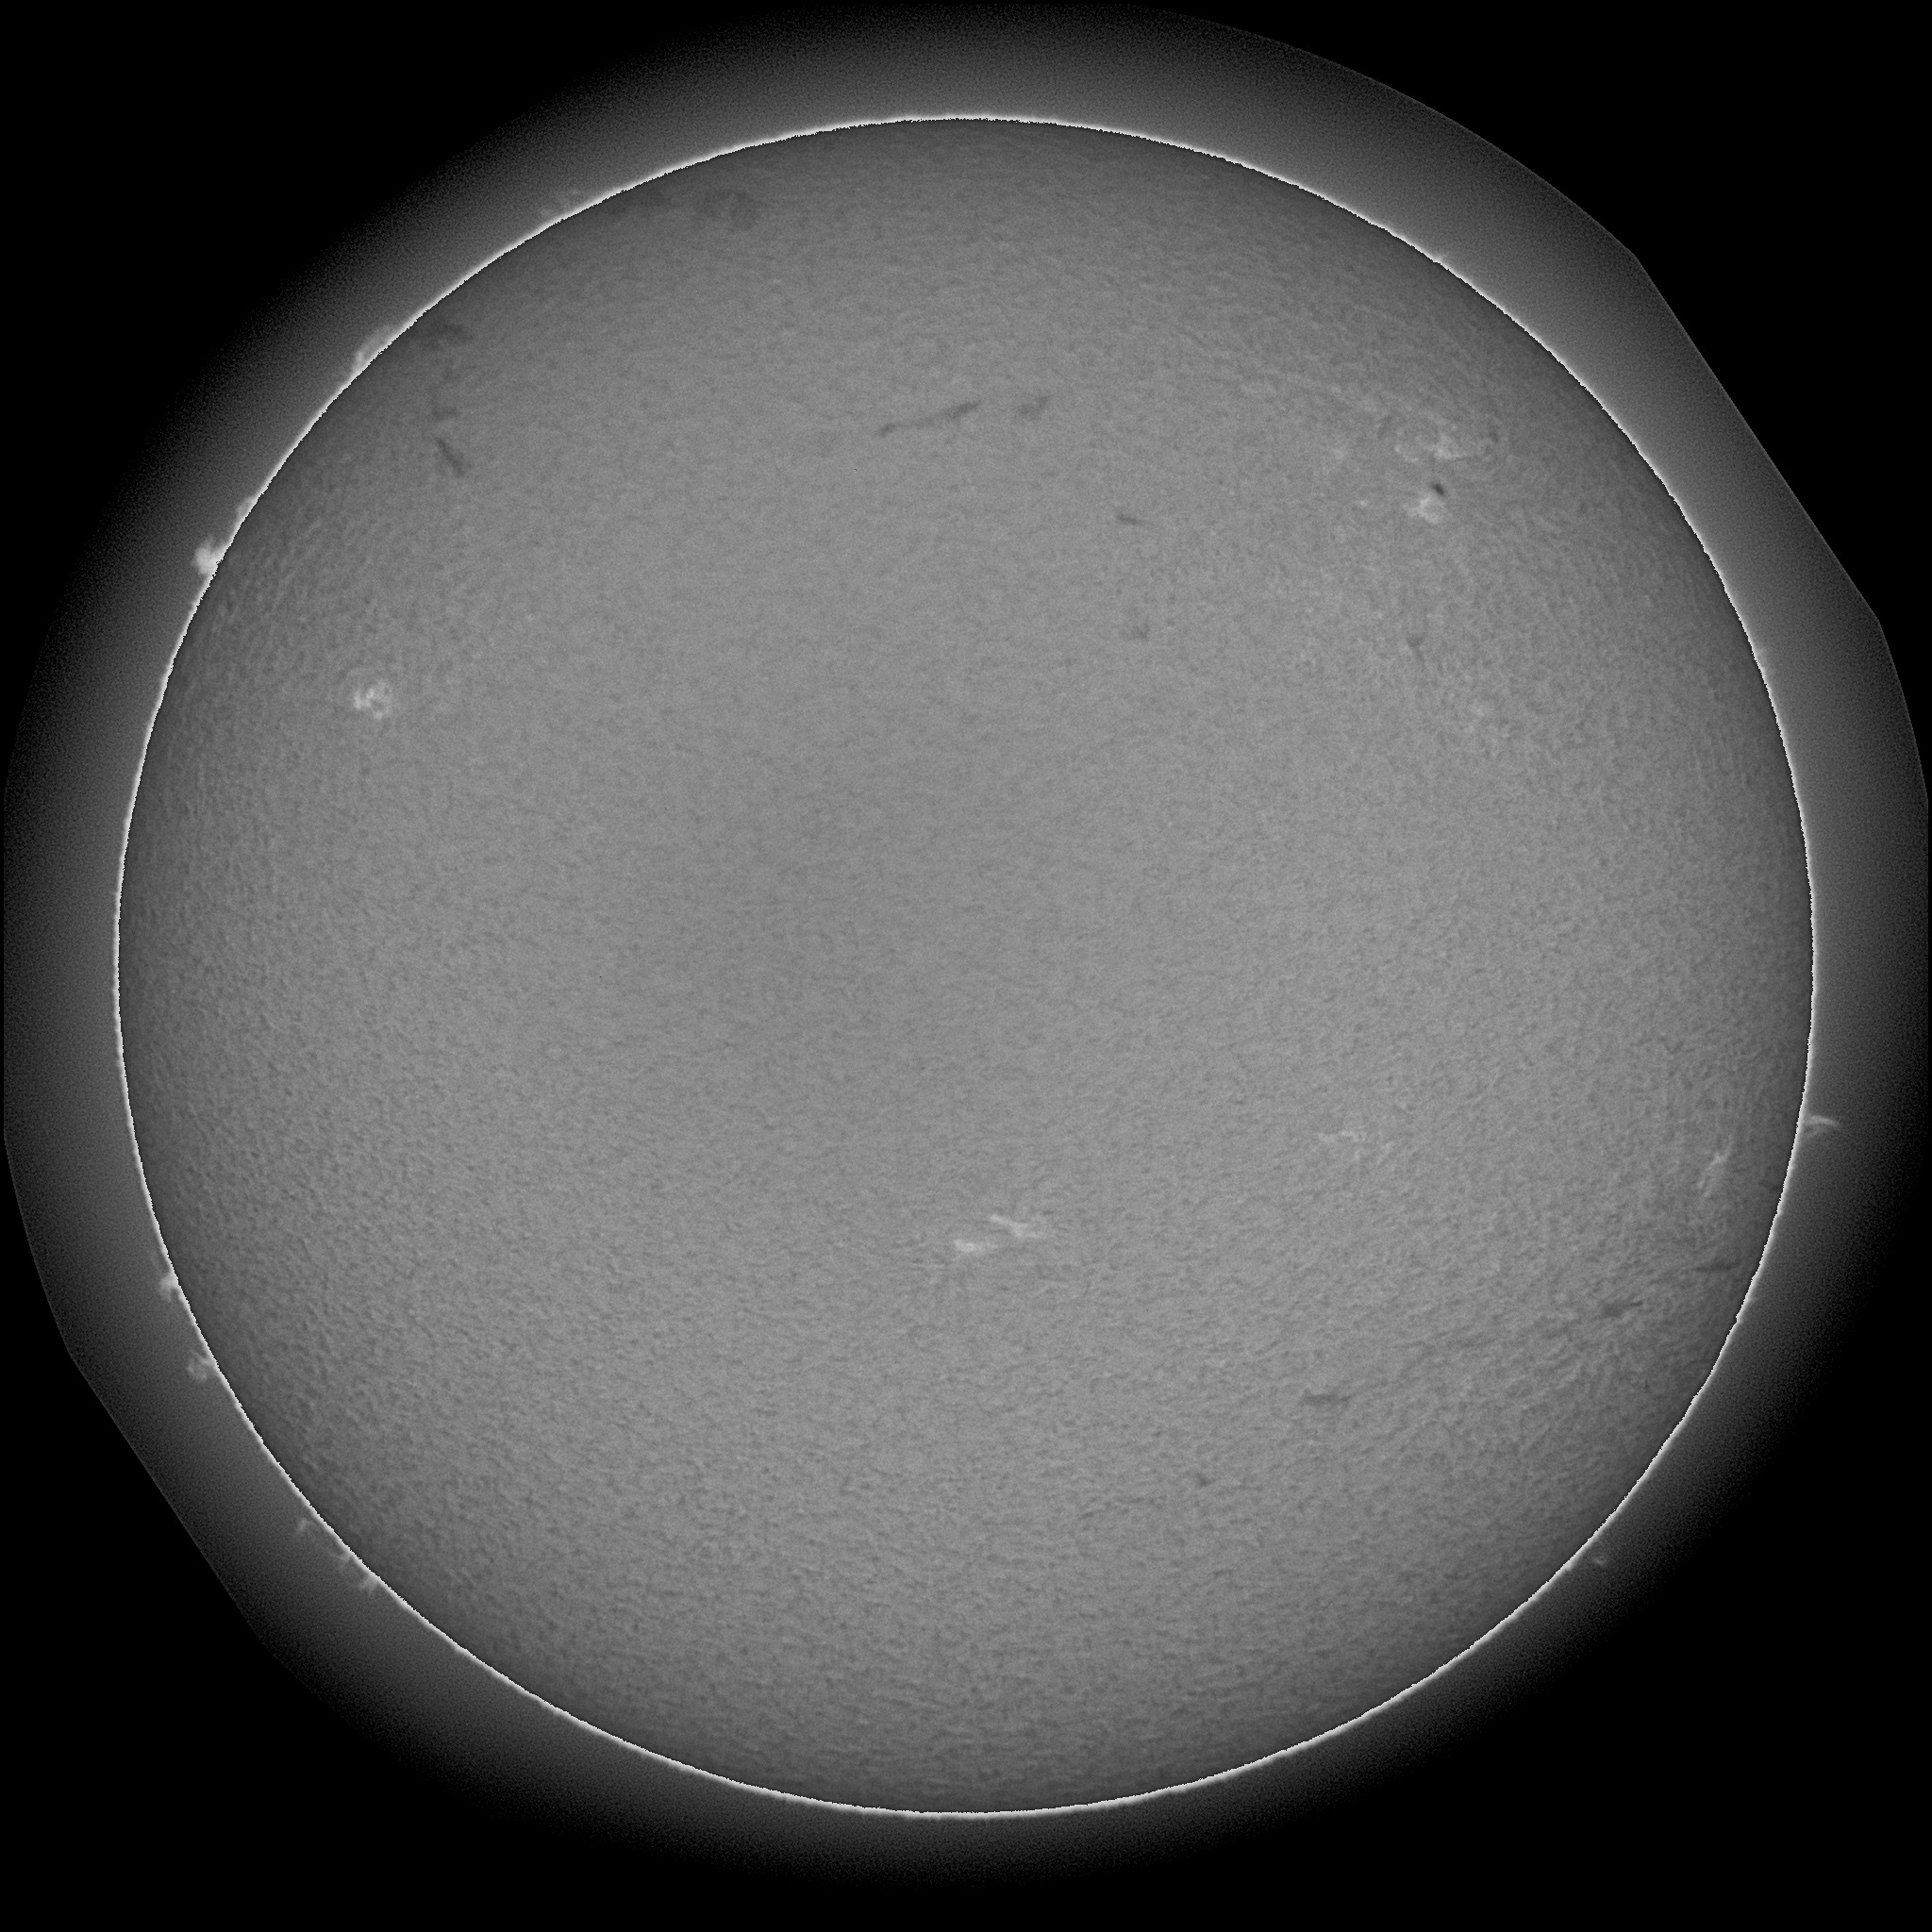
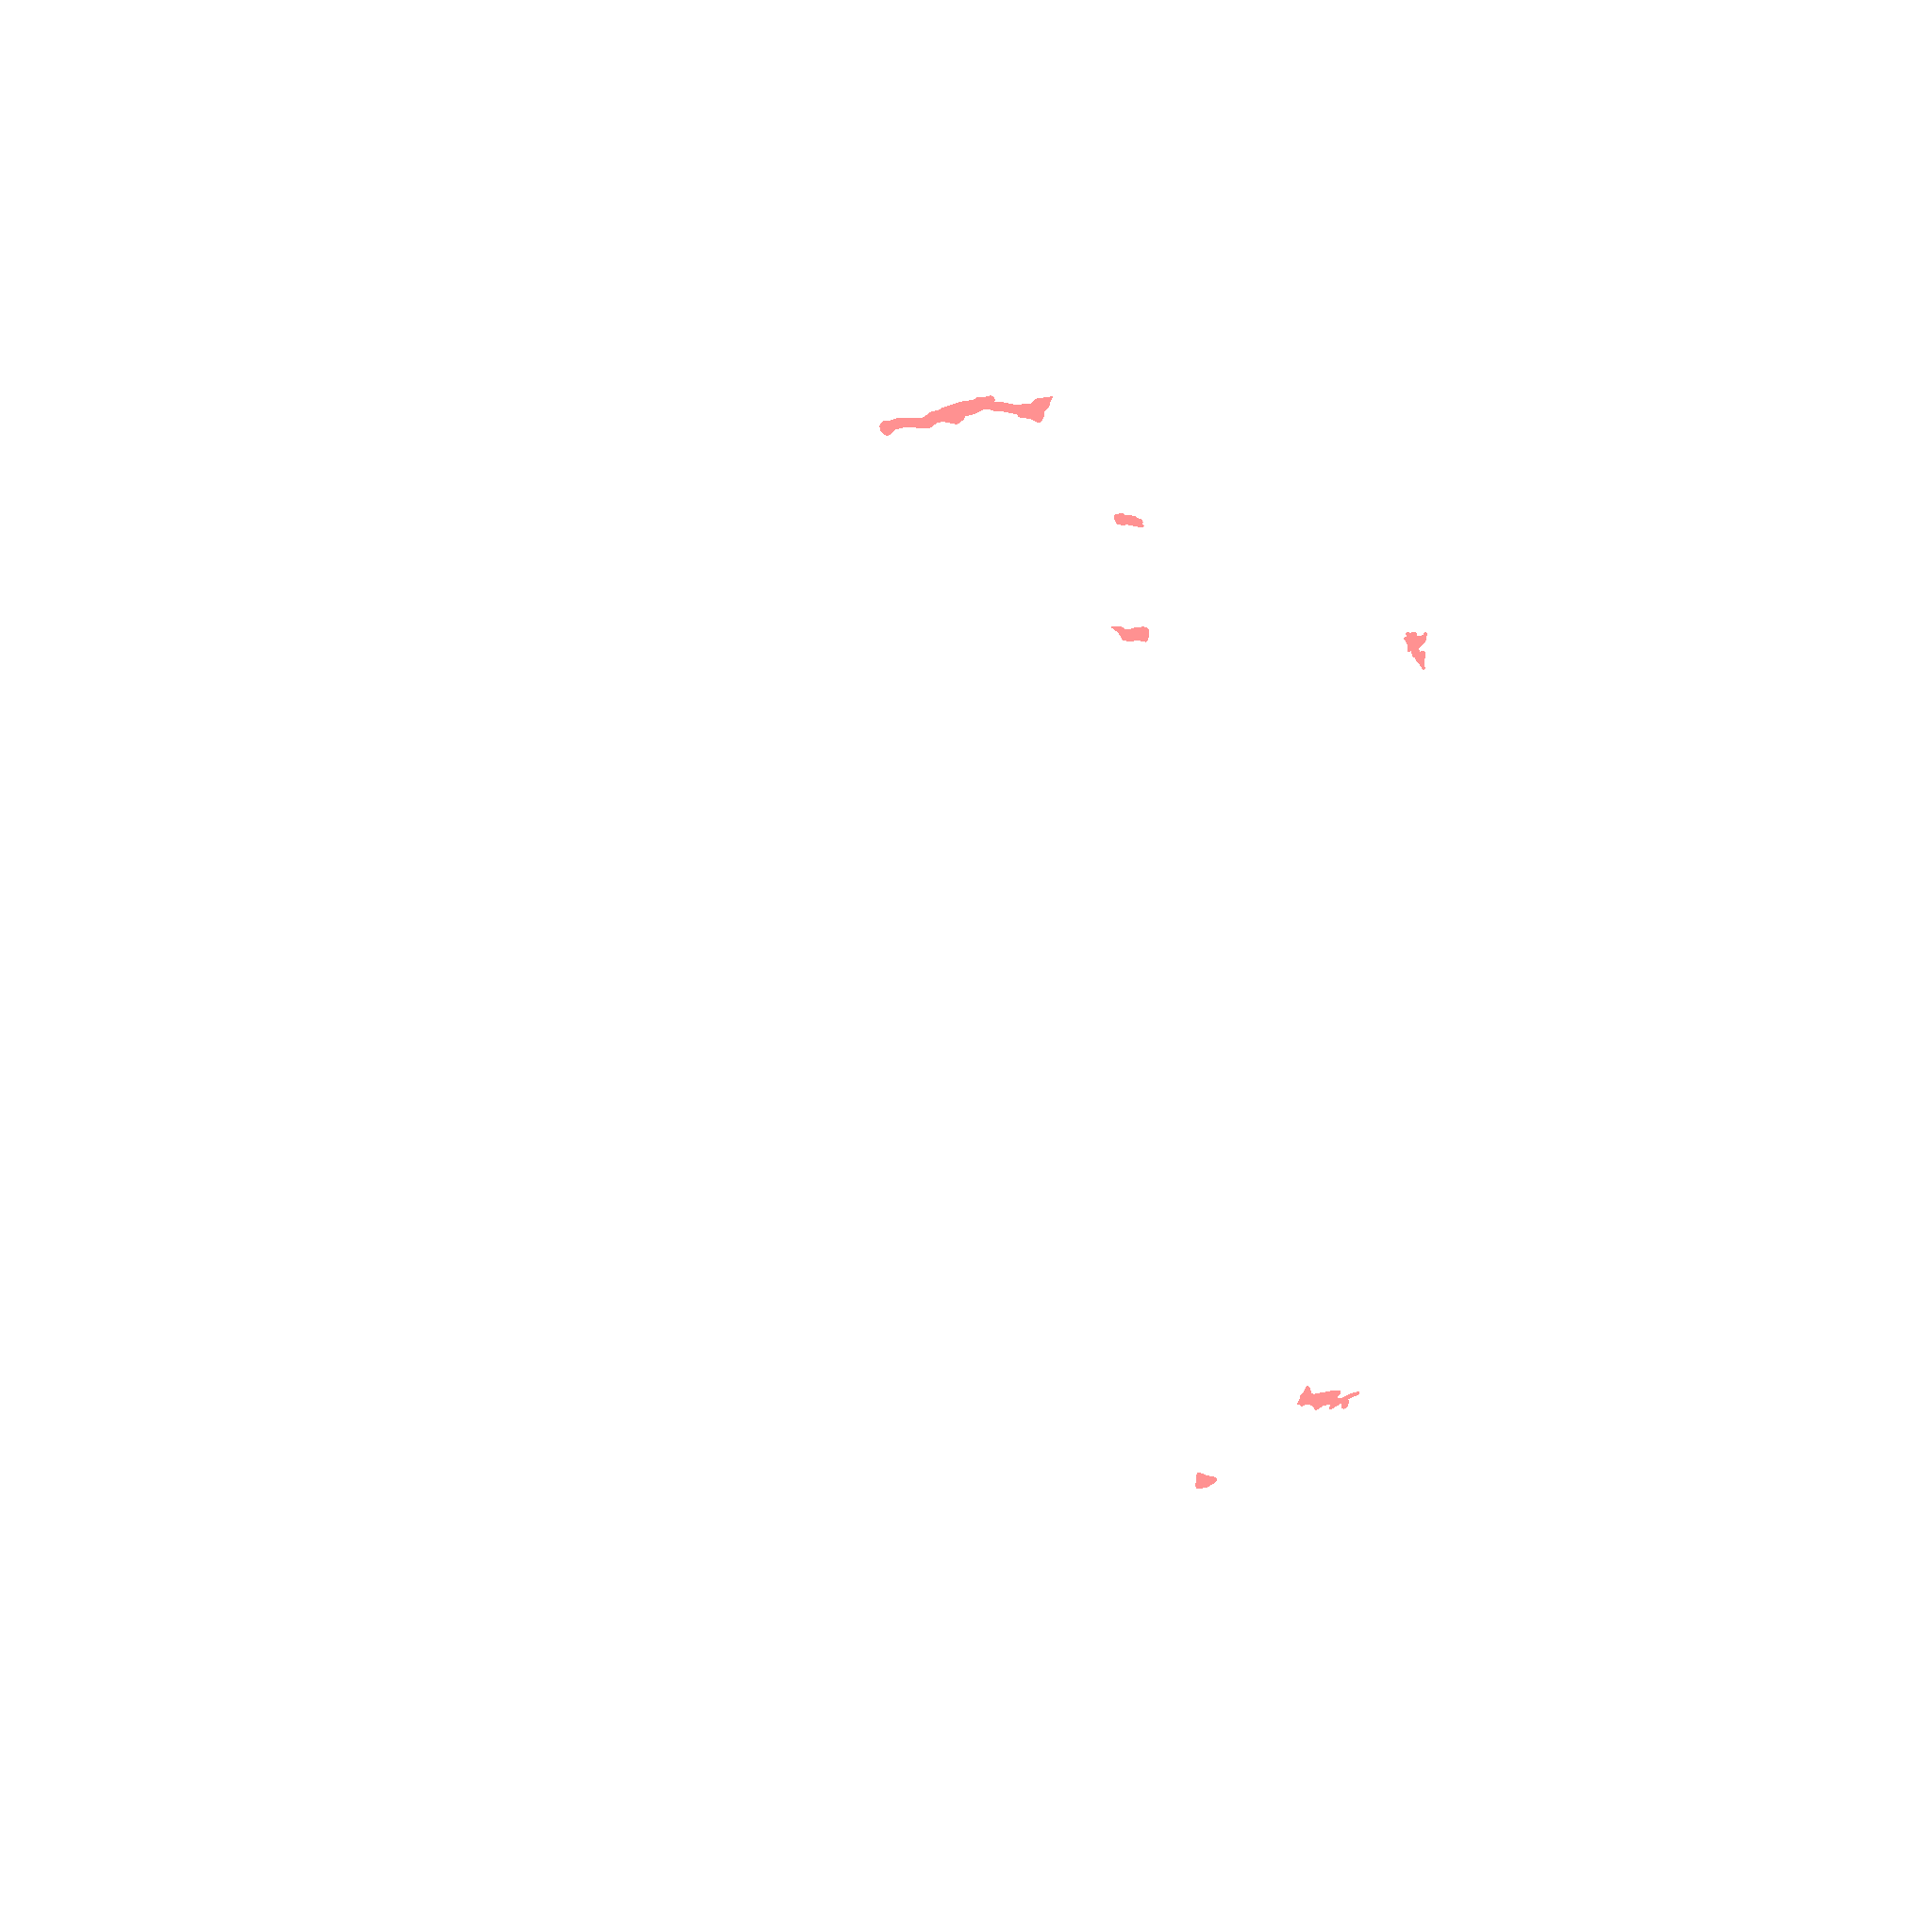

In [ ]:
show_filament_canvas(image_files[0])

Dropdown(description='画像:', layout=Layout(width='600px'), options=('20110109104734Ch.jpeg', '20110114105034Ch.…

/tmp/ipykernel_3811/2847904506.py:13: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(array, mode=mode).save(buffer, format="PNG")



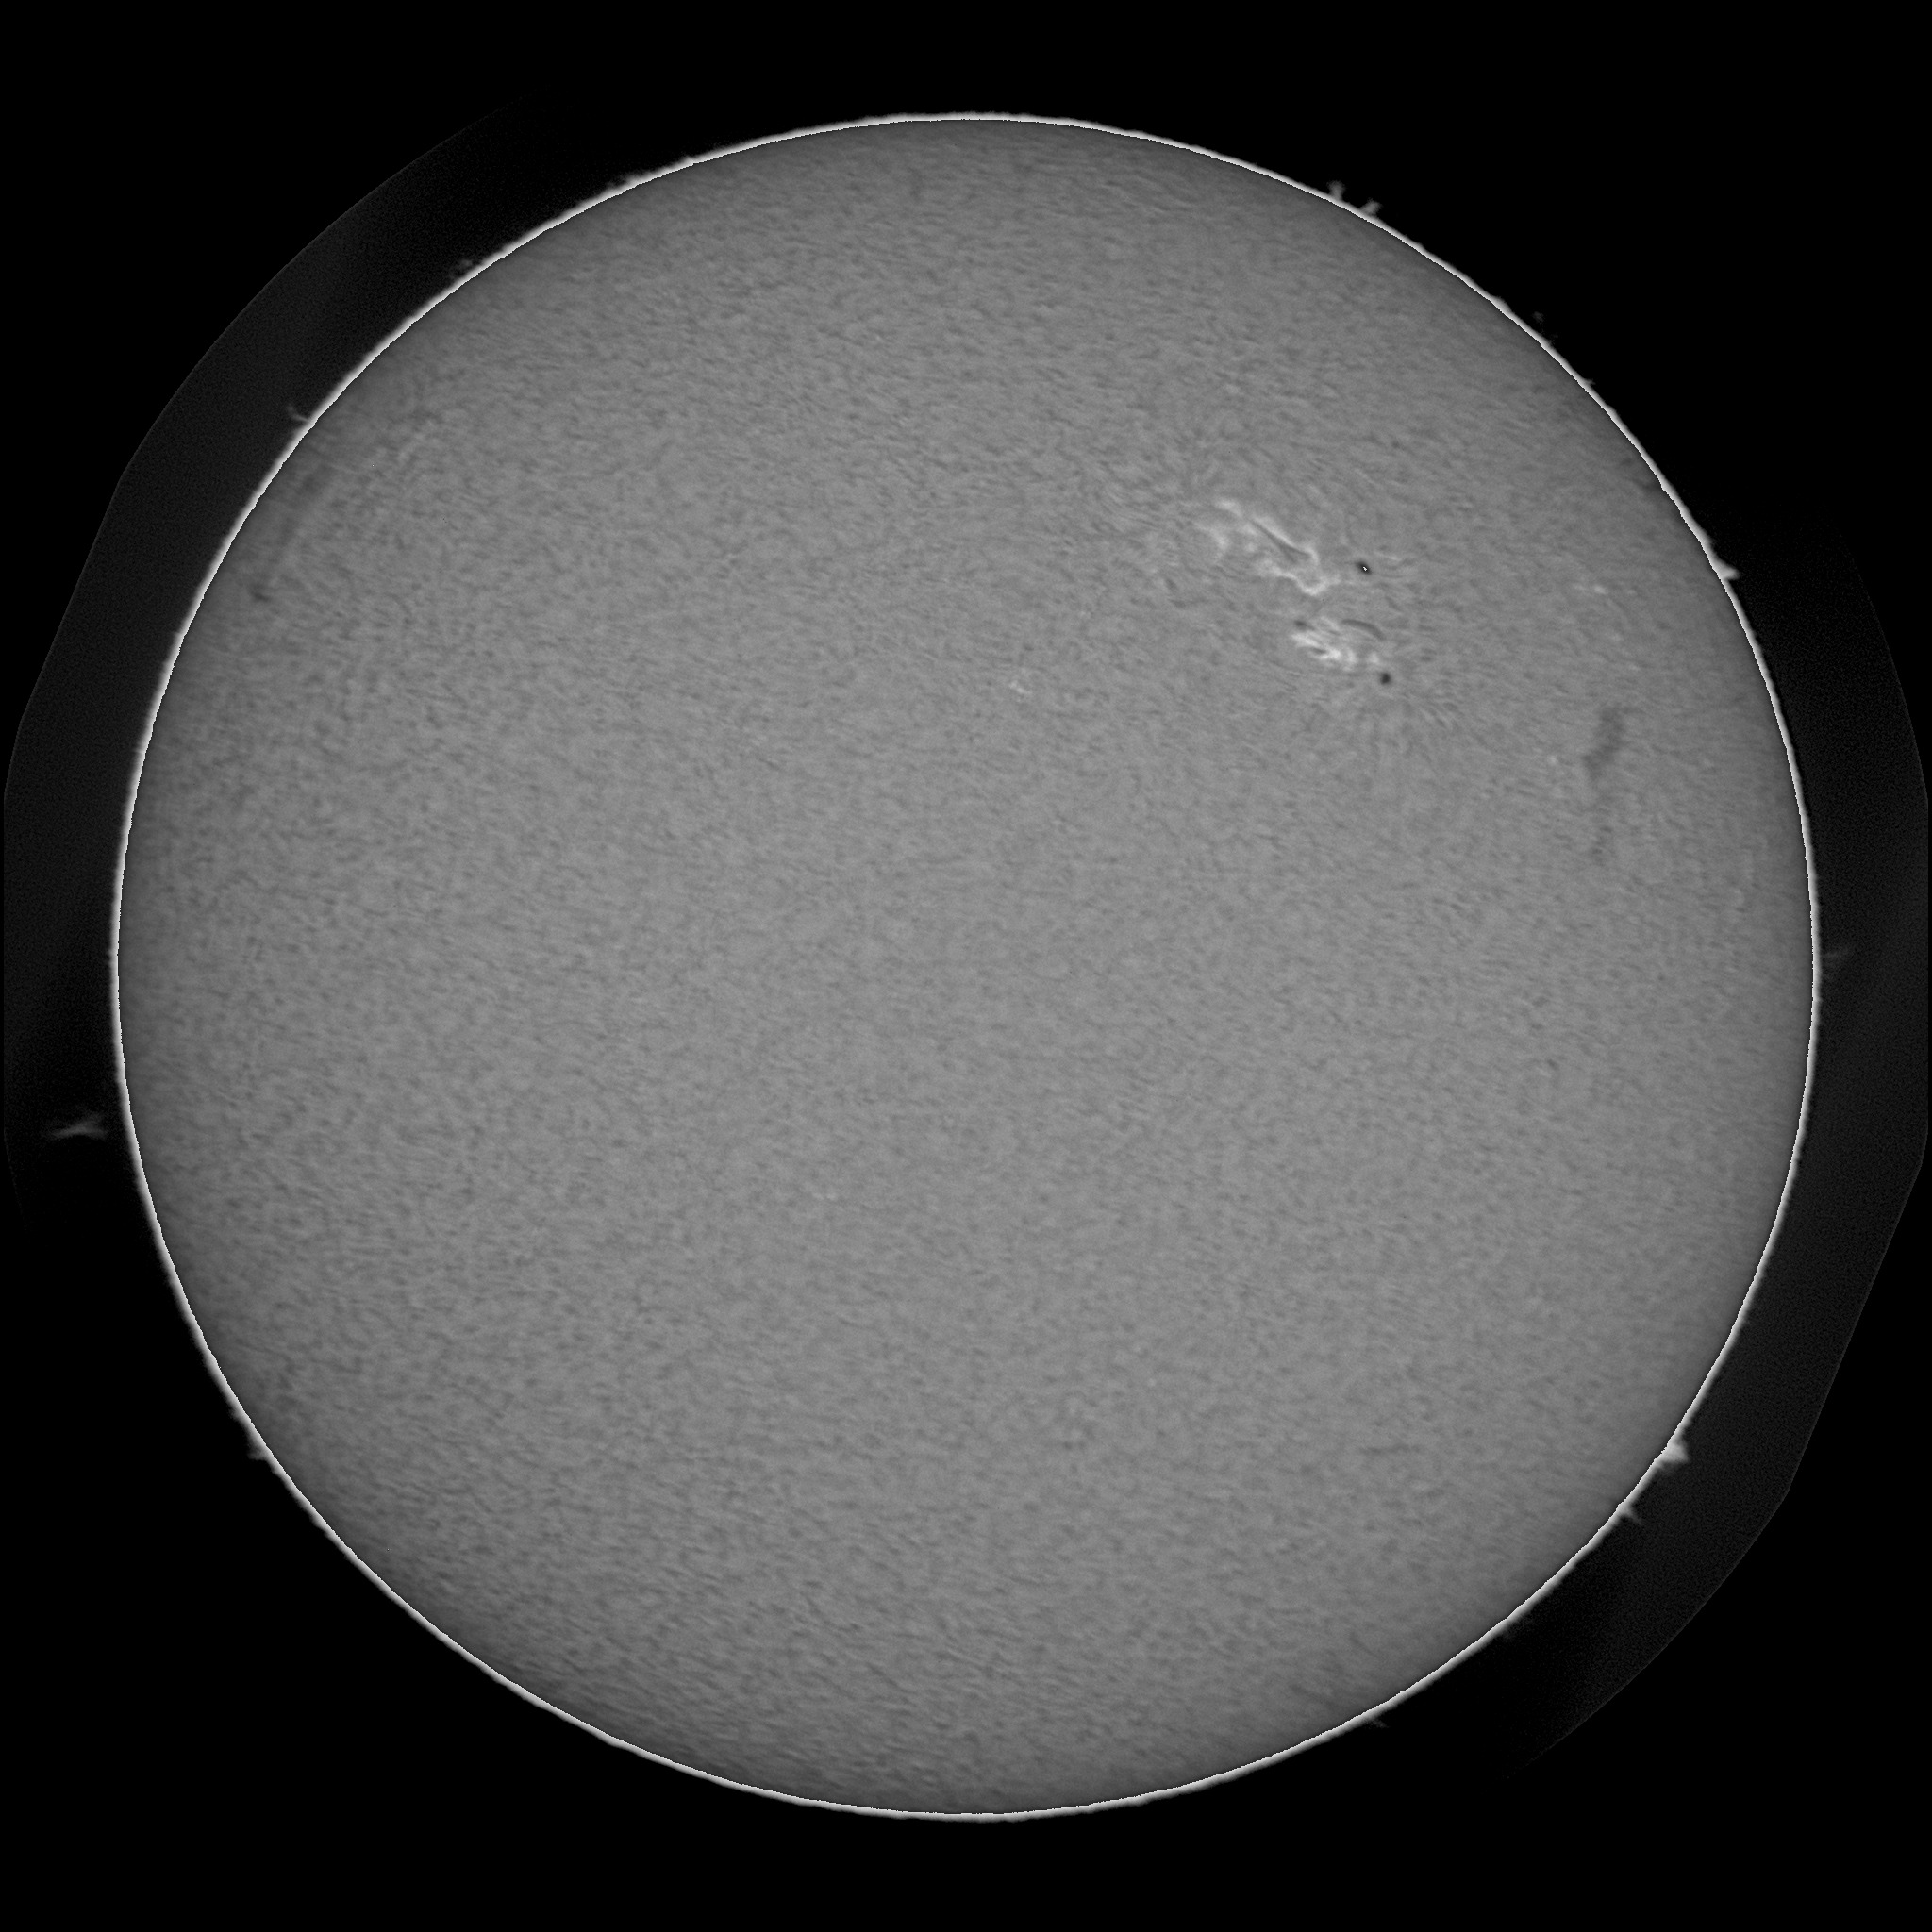
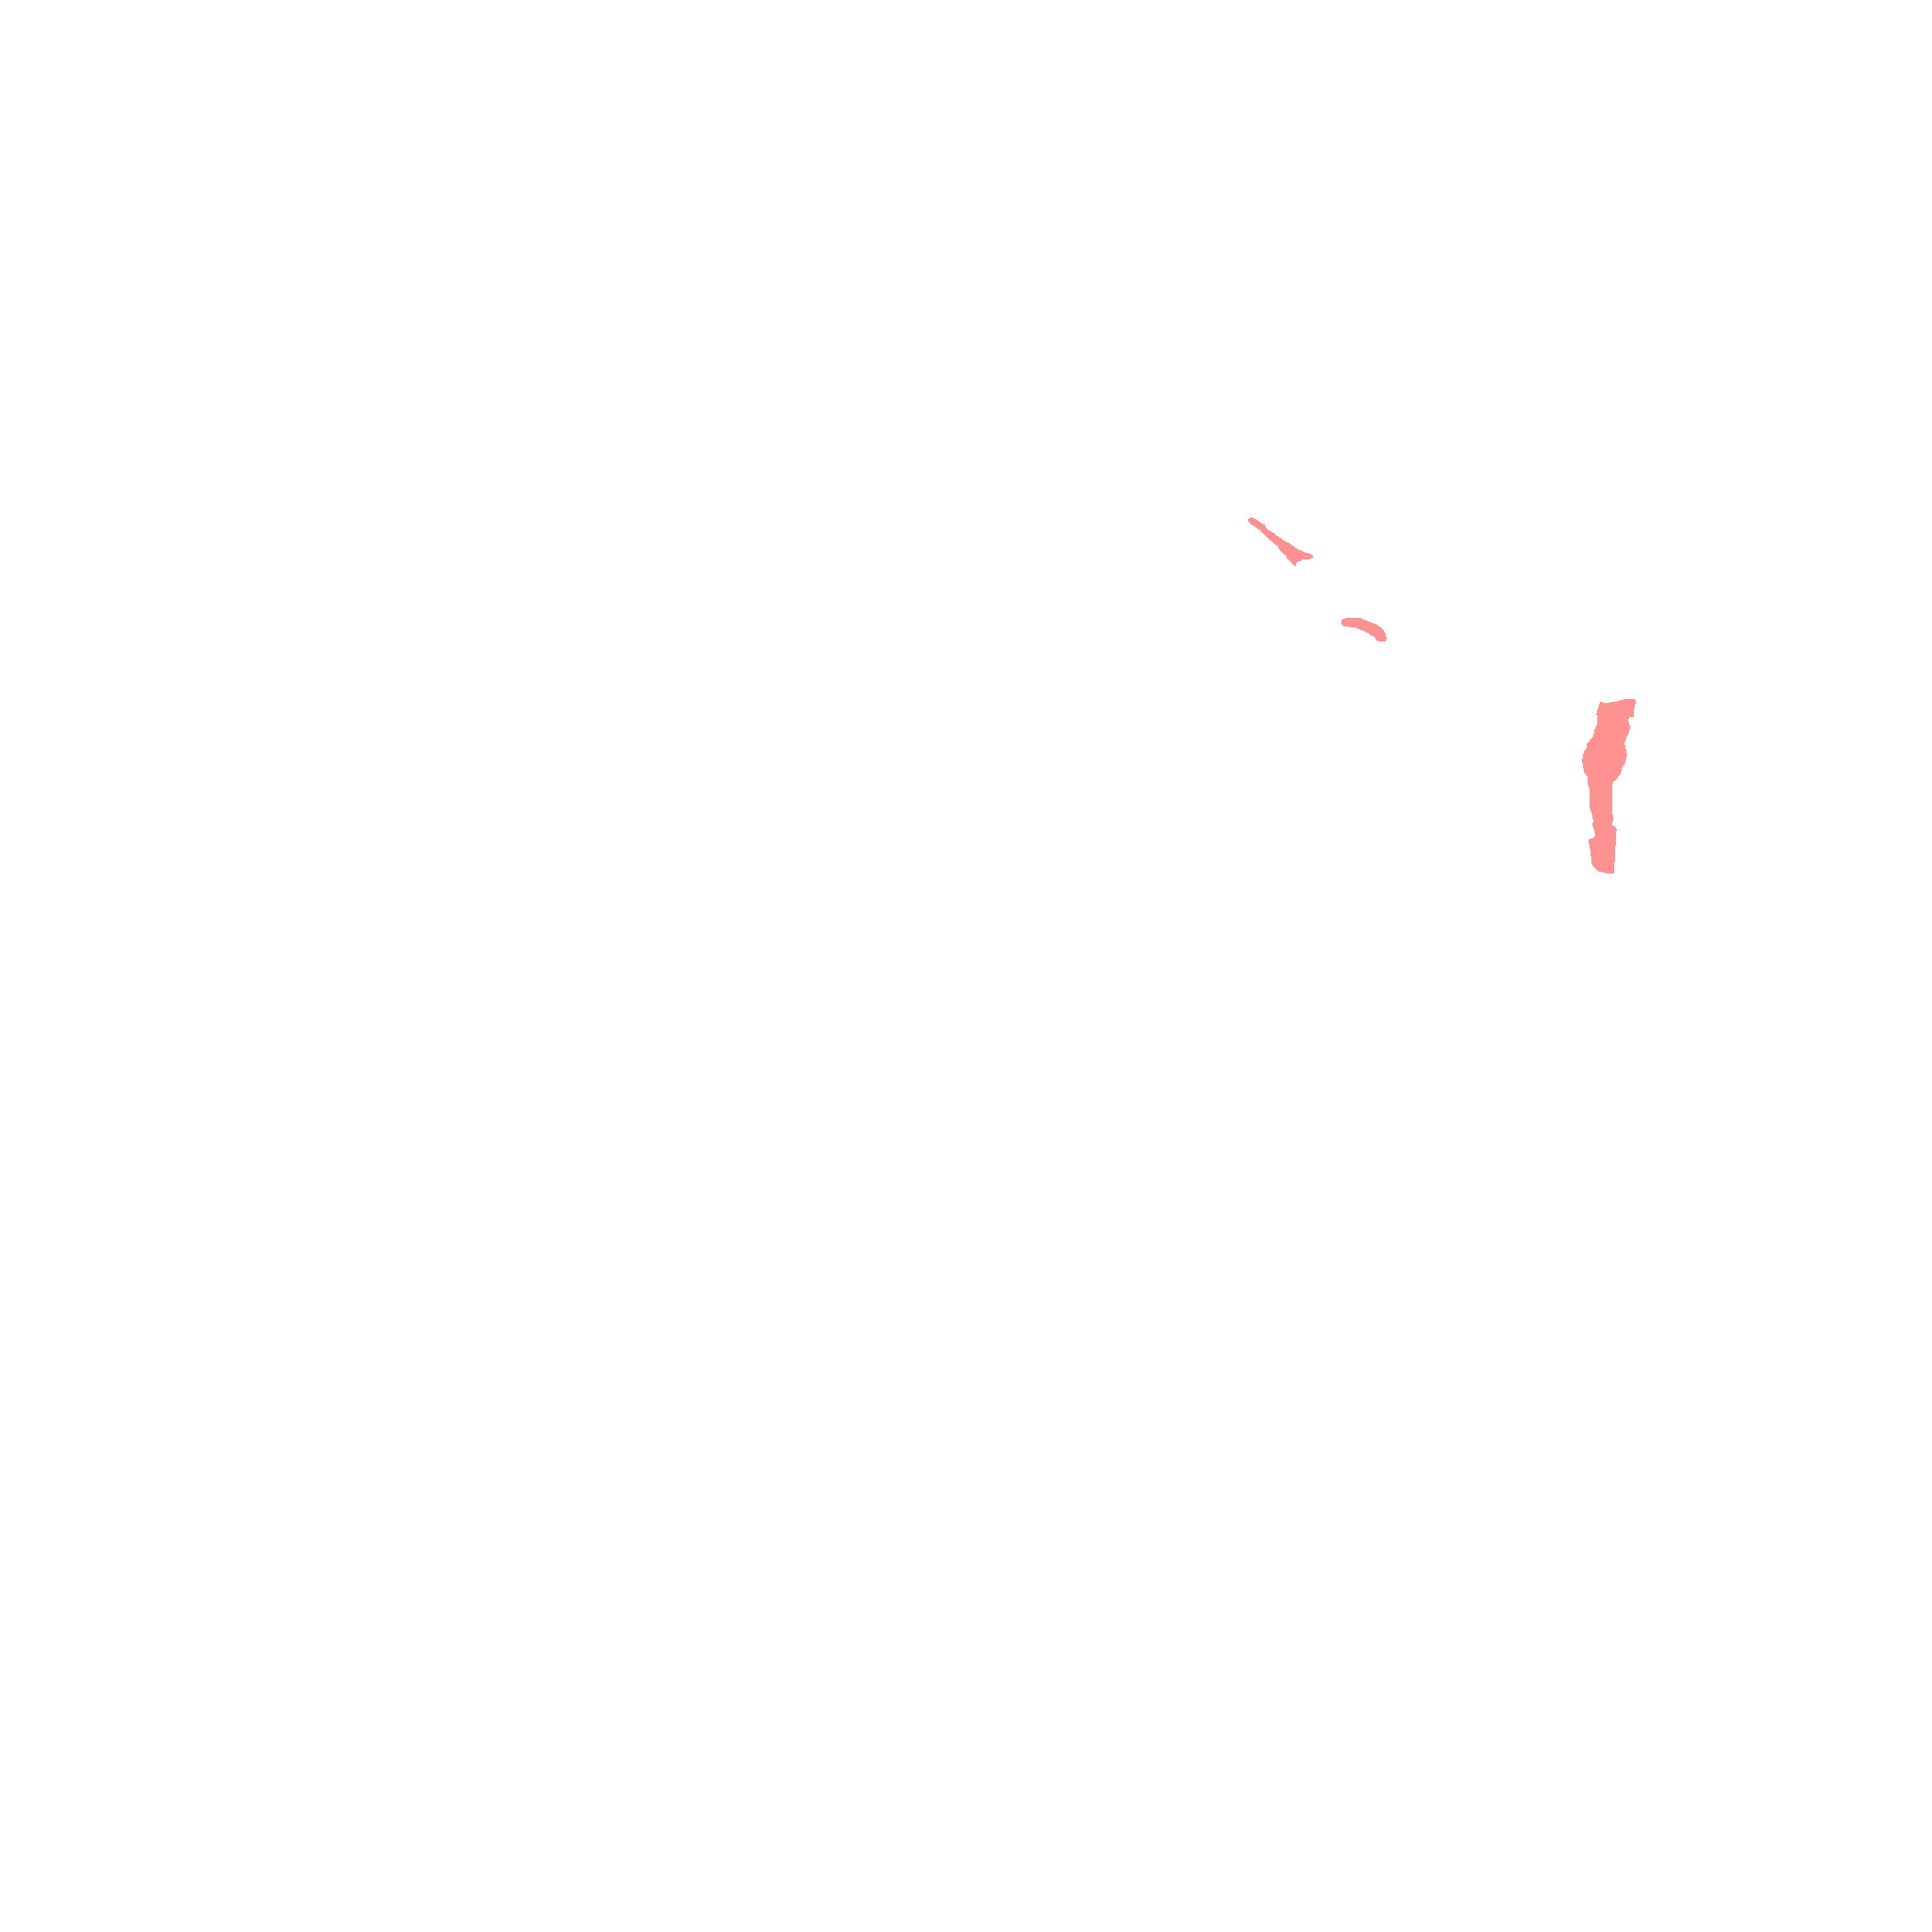

In [ ]:
import ipywidgets as widgets
from IPython.display import display

image_selector = widgets.Dropdown(
    options=image_files,
    value=image_files[0],
    description="画像:",
    layout=widgets.Layout(width="600px")
)

display(image_selector)

def on_image_change(change):
    if change["name"] == "value":
        show_filament_canvas(change["new"])

image_selector.observe(on_image_change, names="value")

In [ ]:
pwd

'/content/drive/MyDrive/kaggle/SolarFilament'

In [ ]:

# ============================================================
# SolarFilament 画像ビューア
#
# 機能
# 1. 画像ファイルをドロップダウンから選択
# 2. COCO形式の正解マスクを元画像に赤色で重ねて表示
# 3. 元画像を左クリックすると、300x300画素をPNG保存
# 4. 保存先は作業ディレクトリ/filament_img/
# 5. 保存名は「元画像名_クリック回数.png」
# 6. 画像の端でも300x300画素を確保
# ============================================================

import os
import sys
import json
import glob
import base64
import io
import subprocess
from pathlib import Path
from collections import defaultdict

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

from IPython.display import display, HTML, clear_output
import ipywidgets as widgets
from google.colab import output


# ------------------------------------------------------------
# 1. データセットの場所を設定
# ------------------------------------------------------------

# 必要に応じて、ここを実際のデータセットの場所に変更してください。
DATASET_DIR = Path("/content")

IMAGE_DIR_CANDIDATES = [
    DATASET_DIR / "train" / "train_images",
    DATASET_DIR / "MAGFiLO_1.0_Kaggle_2026" / "train" / "train_images",
    Path("train/train_images"),
    Path("../train/train_images"),
]

JSON_NAME = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"

JSON_CANDIDATES = [
    DATASET_DIR / "train" / JSON_NAME,
    DATASET_DIR / "MAGFiLO_1.0_Kaggle_2026" / "train" / JSON_NAME,
    Path("train") / JSON_NAME,
    Path("../train") / JSON_NAME,
]


def first_existing(paths, is_dir=False):
    for path in paths:
        if path.exists() and (path.is_dir() if is_dir else path.is_file()):
            return path.resolve()
    return None


IMAGE_DIR = first_existing(IMAGE_DIR_CANDIDATES, is_dir=True)
JSON_PATH = first_existing(JSON_CANDIDATES)

# 候補から見つからない場合は、/content以下を検索
if IMAGE_DIR is None:
    matches = glob.glob(
        "/content/**/train_images",
        recursive=True
    )
    matches = [Path(p) for p in matches if Path(p).is_dir()]
    if matches:
        IMAGE_DIR = matches[0].resolve()

if JSON_PATH is None:
    matches = glob.glob(
        f"/content/**/{JSON_NAME}",
        recursive=True
    )
    matches = [Path(p) for p in matches if Path(p).is_file()]
    if matches:
        JSON_PATH = matches[0].resolve()

if IMAGE_DIR is None:
    raise FileNotFoundError(
        "画像フォルダ train_images が見つかりません。\n"
        "IMAGE_DIR_CANDIDATES または DATASET_DIR を確認してください。"
    )

if JSON_PATH is None:
    raise FileNotFoundError(
        f"アノテーションJSONが見つかりません: {JSON_NAME}\n"
        "JSON_CANDIDATES を実際の場所に合わせてください。"
    )

print("画像フォルダ:", IMAGE_DIR)
print("JSONファイル:", JSON_PATH)


# ------------------------------------------------------------
# 2. 必要なライブラリ pycocotools
# ------------------------------------------------------------

try:
    from pycocotools import mask as mask_utils
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "pycocotools"
    ])
    from pycocotools import mask as mask_utils


# ------------------------------------------------------------
# 3. JSONと画像一覧を読み込む
# ------------------------------------------------------------

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco_data = json.load(f)

image_records = coco_data.get("images", [])
annotations = coco_data.get("annotations", [])

# ファイル名から画像IDを検索
image_id_by_name = {}
for record in image_records:
    name = os.path.basename(record["file_name"])
    image_id_by_name[name] = record["id"]

# 画像IDからアノテーションを検索
annotations_by_id = defaultdict(list)
for ann in annotations:
    annotations_by_id[ann["image_id"]].append(ann)

# 対応する画像ファイルを列挙
image_files = sorted(
    [
        p.name
        for p in IMAGE_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".tif", ".tiff"]
    ]
)

if not image_files:
    raise FileNotFoundError(
        f"画像ファイルがありません: {IMAGE_DIR}"
    )

print(f"画像数: {len(image_files)}")
print(f"アノテーション数: {len(annotations)}")


# ------------------------------------------------------------
# 4. 画像と正解マスクを読み込む関数
# ------------------------------------------------------------

def load_image_and_mask(filename):
    image_path = IMAGE_DIR / filename

    # グレースケール画像として読み込む
    image = np.array(
        Image.open(image_path).convert("L"),
        dtype=np.uint8
    )

    height, width = image.shape
    mask = np.zeros((height, width), dtype=np.uint8)

    image_id = image_id_by_name.get(os.path.basename(filename))

    if image_id is None:
        return image, mask

    for ann in annotations_by_id.get(image_id, []):
        seg = ann.get("segmentation")

        if not seg:
            continue

        try:
            # COCOのRLE形式
            if isinstance(seg, dict):
                rle = seg

                # 圧縮されていないRLEの場合は変換
                if isinstance(rle.get("counts"), list):
                    rle = mask_utils.frPyObjects(
                        rle, height, width
                    )

            # COCOのポリゴン形式
            elif isinstance(seg, list):
                polygons = [
                    p for p in seg
                    if isinstance(p, list) and len(p) >= 6
                ]

                if not polygons:
                    continue

                rles = mask_utils.frPyObjects(
                    polygons, height, width
                )
                rle = mask_utils.merge(rles)

            else:
                continue

            decoded = mask_utils.decode(rle)

            # 複数領域をまとめて1枚のマスクにする
            if decoded.ndim == 3:
                decoded = np.any(decoded, axis=2)

            mask |= decoded.astype(np.uint8)

        except Exception as e:
            print(
                f"マスクの読み込みをスキップ: {filename}, "
                f"annotation id={ann.get('id')}: {e}"
            )

    return image, mask


# ------------------------------------------------------------
# 5. PNG画像をブラウザ用データに変換
# ------------------------------------------------------------

def png_data_url(array, mode):
    buffer = io.BytesIO()
    Image.fromarray(array, mode=mode).save(
        buffer, format="PNG"
    )
    encoded = base64.b64encode(
        buffer.getvalue()
    ).decode("ascii")
    return "data:image/png;base64," + encoded


# ------------------------------------------------------------
# 6. クリック位置の300x300画像を保存する関数
# ------------------------------------------------------------

SAVE_DIR = Path.cwd() / "filament_img"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 画像ごとにクリック回数を記録
click_counts = defaultdict(int)


def save_filament_crop(filename, x, y):
    image, _ = load_image_and_mask(filename)

    height, width = image.shape
    crop_size = 300

    if width < crop_size or height < crop_size:
        raise ValueError(
            f"画像サイズが小さすぎます: {width}x{height}"
        )

    # クリック座標を画像内に収める
    x = int(np.clip(round(x), 0, width - 1))
    y = int(np.clip(round(y), 0, height - 1))

    # クリック位置を中心にする。
    # 端では切り出し領域を画像内にずらす。
    left = max(0, min(x - crop_size // 2, width - crop_size))
    top = max(0, min(y - crop_size // 2, height - crop_size))

    crop = image[
        top:top + crop_size,
        left:left + crop_size
    ]

    click_counts[filename] += 1
    click_number = click_counts[filename]

    stem = Path(filename).stem
    save_path = SAVE_DIR / f"{stem}_{click_number}.png"

    # PNG形式で保存。JPEGへの変換は行わない
    Image.fromarray(crop).save(save_path, format="PNG")

    print(
        f"保存完了: {save_path}\n"
        f"クリック座標: ({x}, {y})\n"
        f"切り出し左上: ({left}, {top})\n"
        f"画像サイズ: {crop.shape[1]} x {crop.shape[0]}"
    )

    return str(save_path)


# ColabのJavaScriptから呼び出せるように登録
output.register_callback(
    "notebook.save_filament_crop",
    save_filament_crop
)


# ------------------------------------------------------------
# 7. Canvas画像ビューア
# ------------------------------------------------------------

def show_filament_canvas(filename):
    image, mask = load_image_and_mask(filename)

    height, width = image.shape

    # 正解マスクを半透明の赤色にする
    overlay = np.zeros((height, width, 4), dtype=np.uint8)
    overlay[mask > 0] = [255, 0, 0, 110]

    image_url = png_data_url(image, "L")
    mask_url = png_data_url(overlay, "RGBA")

    # HTML内のIDを画像表示ごとに一意にする
    import uuid
    uid = "solar_" + uuid.uuid4().hex[:10]

    html = r"""
    <div id="__ROOT_ID__"
         style="font-family:sans-serif; max-width:100%;">

      <div style="margin-bottom:8px;">
        <b>画像：</b> __FILENAME__
        <br>
        <span style="color:#555;">
          左クリック：300×300画像をPNG保存
          ／ 赤色：正解マスク
        </span>
      </div>

      <div style="display:flex; flex-wrap:wrap; gap:16px;
                  align-items:flex-start;">

        <div style="flex:1; min-width:280px;">
          <canvas id="__MAIN_ID__"
                  width="__WIDTH__" height="__HEIGHT__"
                  style="width:100%; height:auto;
                         max-width:800px; border:1px solid #888;
                         cursor:crosshair;"></canvas>
        </div>

        <div style="min-width:220px; max-width:320px;">
          <b>クリック情報</b>
          <div id="__STATUS_ID__"
               style="margin-top:8px; white-space:pre-wrap;
                      overflow-wrap:anywhere;">
            画像を左クリックしてください。
          </div>
          <hr>
          <div>
            保存先：filament_img/
          </div>
          <div style="font-size:12px;color:#555;">
            保存形式：PNG（300×300画素）
          </div>
        </div>
      </div>
    </div>

    <script>
    (() => {
        const root = document.getElementById("__ROOT_ID__");
        const main = document.getElementById("__MAIN_ID__");
        const status = document.getElementById("__STATUS_ID__");
        const ctx = main.getContext("2d");

        const image = new Image();
        const maskImage = new Image();

        const filename = __FILENAME_JSON__;
        const imageUrl = "__IMAGE_URL__";
        const maskUrl = "__MASK_URL__";

        let ready = false;

        function canvasPoint(event) {
            const rect = main.getBoundingClientRect();
            return {
                x: (event.clientX - rect.left) * main.width / rect.width,
                y: (event.clientY - rect.top) * main.height / rect.height
            };
        }

        function redraw() {
            ctx.clearRect(0, 0, main.width, main.height);
            ctx.drawImage(image, 0, 0, main.width, main.height);
            ctx.drawImage(maskImage, 0, 0, main.width, main.height);
        }

        function onLoaded() {
            if (!image.complete || !maskImage.complete) return;
            if (!image.naturalWidth || !maskImage.naturalWidth) return;

            redraw();
            ready = true;
        }

        image.onload = onLoaded;
        maskImage.onload = onLoaded;

        image.onerror = () => {
            status.textContent = "元画像を読み込めませんでした。";
        };
        maskImage.onerror = () => {
            status.textContent = "マスク画像を読み込めませんでした。";
        };

        image.src = imageUrl;
        maskImage.src = maskUrl;

        // 左クリックで300x300画像を保存
        main.addEventListener("click", async (event) => {
            if (!ready) return;

            const p = canvasPoint(event);
            const x = Math.max(
                0, Math.min(main.width - 1, Math.round(p.x))
            );
            const y = Math.max(
                0, Math.min(main.height - 1, Math.round(p.y))
            );

            status.textContent =
                `保存中...\n座標: (${x}, ${y})`;

            try {
                const result = await google.colab.kernel.invokeFunction(
                    "notebook.save_filament_crop",
                    [filename, x, y],
                    {}
                );

                status.textContent =
                    `保存しました。\n座標: (${x}, ${y})\n` +
                    `保存先: filament_img/`;

            } catch (error) {
                status.textContent = "保存に失敗しました。\n" + error;
                console.error(error);
            }
        });

        // ブラウザの右クリックメニューをキャンバス上で抑制
        main.addEventListener("contextmenu", (event) => {
            event.preventDefault();
        });
    })();
    </script>
    """

    # 一意なプレースホルダーだけを置換する
    replacements = {
        "__ROOT_ID__": uid + "_root",
        "__MAIN_ID__": uid + "_main",
        "__STATUS_ID__": uid + "_status",
        "__FILENAME__": filename,
        "__FILENAME_JSON__": json.dumps(filename),
        "__WIDTH__": str(width),
        "__HEIGHT__": str(height),
        "__IMAGE_URL__": image_url,
        "__MASK_URL__": mask_url,
    }

    for old, new in replacements.items():
        html = html.replace(old, new)

    display(HTML(html))


# ------------------------------------------------------------
# 8. ドロップダウンで画像を切り替える
# ------------------------------------------------------------

image_dropdown = widgets.Dropdown(
    options=image_files,
    value=image_files[0],
    description="画像選択:",
    layout=widgets.Layout(width="500px")
)

viewer_output = widgets.Output()


def on_image_change(change):
    if change["name"] != "value":
        return

    with viewer_output:
        clear_output(wait=True)
        show_filament_canvas(change["new"])


image_dropdown.observe(on_image_change, names="value")

display(image_dropdown)
display(viewer_output)

with viewer_output:
    show_filament_canvas(image_dropdown.value)

print("準備完了")
print("保存先:", SAVE_DIR)


画像フォルダ: /content/drive/MyDrive/kaggle/SolarFilament/train/train_images
JSONファイル: /content/drive/MyDrive/kaggle/SolarFilament/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
画像数: 707
アノテーション数: 8199


Dropdown(description='画像選択:', layout=Layout(width='500px'), options=('20110109104734Ch.jpeg', '20110114105034C…

Output()

準備完了
保存先: /content/drive/MyDrive/kaggle/SolarFilament/filament_img
保存完了: /content/drive/MyDrive/kaggle/SolarFilament/filament_img/20110211084114Th_1.png
クリック座標: (1099, 313)
切り出し左上: (949, 163)
画像サイズ: 300 x 300
保存完了: /content/drive/MyDrive/kaggle/SolarFilament/filament_img/20110211084114Th_2.png
クリック座標: (965, 1231)
切り出し左上: (815, 1081)
画像サイズ: 300 x 300
保存完了: /content/drive/MyDrive/kaggle/SolarFilament/filament_img/20110211084114Th_3.png
クリック座標: (513, 1255)
切り出し左上: (363, 1105)
画像サイズ: 300 x 300


In [ ]:
ls

filament_img/  test/  train/  Untitled0.ipynb


In [ ]:
ls ./filament_img/

20110211084114Th_1.png  20110211084114Th_2.png  20110211084114Th_3.png


今回の領域分割は、Seed（種点）を50個配置し、Enterキーを押すたびに各領域を1回ずつ膨張させる、ステップ実行型の領域成長法として実装します。
Google Colabでは、通常のターミナルのように input() でEnterキーを待つと、画像を確認しながら操作しにくいため、画面上のボタンで1ステップずつ進める方法が安定しています。今回は、Enterキーでもボタンでも次の膨張処理に進めるようにします。
- 左側：元画像 20110211084114Th_1.png
- 右側：ラベリング画像。各Seedの領域を異なる色で表示
- 初期状態：ランダムなSeedを50個配置
- 1回目：Seedの初期画素値との差が±2以内の8近傍画素をラベル付け
- 2回目以降：各領域の平均値 ± 2標準偏差を判定基準にして膨張
- 領域が拡張しなくなったSeedは停止
- すべてのSeedが停止するまで、Enterキーで1ステップずつ進行

画像サイズ: 300 x 300
画素値の型: uint8


/tmp/ipykernel_3811/811818943.py:299: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(array, mode=mode).save(buf, format="PNG")



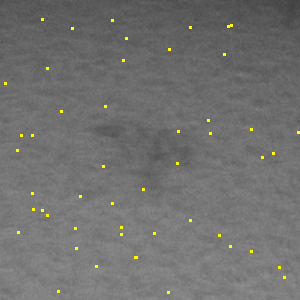
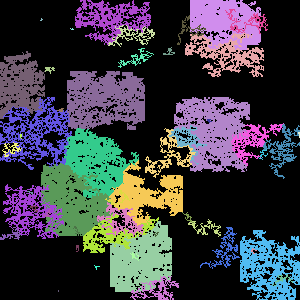

Button(button_style='primary', description='次の膨張処理', icon='step-forward', style=ButtonStyle())

初期状態を表示しました。
ボタンまたはEnterキーで膨張処理を1ステップずつ進めてください。


/tmp/ipykernel_3811/811818943.py:299: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(array, mode=mode).save(buf, format="PNG")
/tmp/ipykernel_3811/811818943.py:299: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(array, mode=mode).save(buf, format="PNG")
/tmp/ipykernel_3811/811818943.py:299: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(array, mode=mode).save(buf, format="PNG")
/tmp/ipykernel_3811/811818943.py:299: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(array, mode=mode).save(buf, format="PNG")
/tmp/ipykernel_3811/811818943.py:299: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(array, mode=mode).save(buf, format="PNG")
/tmp/ipykernel_3811/81181

In [ ]:

import os
import io
import base64
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display, HTML
import ipywidgets as widgets
from google.colab import output


# ============================================================
# 1. 設定
# ============================================================

IMAGE_PATH = "./filament_img/20110211084114Th_1.png"

N_SEEDS = 50
INITIAL_THRESHOLD = 2.0
SIGMA_THRESHOLD = 2.0
RANDOM_SEED = 42

# 8近傍
NEIGHBORS = [
    (-1, -1), (-1, 0), (-1, 1),
    ( 0, -1),           ( 0, 1),
    ( 1, -1), ( 1, 0),  ( 1, 1)
]


# ============================================================
# 2. 元画像の読み込み
# ============================================================

if not os.path.exists(IMAGE_PATH):
    raise FileNotFoundError(
        f"画像が見つかりません: {IMAGE_PATH}\n"
        "IMAGE_PATHを実際の保存場所に合わせてください。"
    )

# グレースケール画像。画素値は0～255
original_image = np.array(
    Image.open(IMAGE_PATH).convert("L"),
    dtype=np.uint8
)

height, width = original_image.shape

print("画像サイズ:", width, "x", height)
print("画素値の型:", original_image.dtype)


# ============================================================
# 3. Seedを50個ランダムに発生
# ============================================================

rng = np.random.default_rng(RANDOM_SEED)

# 同じ画素を複数Seedに割り当てない
seed_flat = rng.choice(
    height * width,
    size=min(N_SEEDS, height * width),
    replace=False
)

seed_yx = [
    (int(p // width), int(p % width))
    for p in seed_flat
]

# ラベリング画像。0は未ラベル、1～50はSeedのラベル
label_image = np.zeros(
    (height, width),
    dtype=np.int32
)

seed_values = np.zeros(len(seed_yx), dtype=np.float64)

for i, (y, x) in enumerate(seed_yx):
    label = i + 1
    label_image[y, x] = label
    seed_values[i] = original_image[y, x]

# 初期Seedの画素値を保存
seed_values_by_label = {
    i + 1: float(original_image[y, x])
    for i, (y, x) in enumerate(seed_yx)
}

# 成長を続けるラベル
active_labels = set(range(1, len(seed_yx) + 1))

# ステップ管理
step_number = 0
first_step_done = False
finished = False


# ============================================================
# 4. ラベリング画像の色を生成
# ============================================================

# ラベル0は黒、各Seedは別々の色
color_rng = np.random.default_rng(RANDOM_SEED + 100)

label_colors = np.zeros(
    (len(seed_yx) + 1, 3),
    dtype=np.uint8
)

for label in range(1, len(seed_yx) + 1):
    # 暗すぎない色を作る
    label_colors[label] = color_rng.integers(
        50, 256, size=3
    )


# ============================================================
# 5. 現在のラベル領域の平均と標準偏差
# ============================================================

def get_region_statistics(label):
    """
    現在のラベル領域の平均・標準偏差を計算。
    面積が3画素以下なら標準偏差を1とする。
    """
    pixels = original_image[label_image == label]

    if len(pixels) == 0:
        return 0.0, 1.0, 0

    mean_value = float(np.mean(pixels))
    area = int(len(pixels))

    if area <= 3:
        std_value = 1.0
    else:
        std_value = float(np.std(pixels))

    # 標準偏差0でも判定幅が完全に0にならないようにする
    std_value = max(std_value, 1e-6)

    return mean_value, std_value, area


# ============================================================
# 6. 1回の膨張処理
# ============================================================

def grow_one_step():
    """
    Enterキーまたはボタン1回につき1回呼び出す。

    第1ステップ:
        Seedの初期画素値との差が±2以内の8近傍を取得。

    第2ステップ以降:
        各領域の平均±2標準偏差で新しい画素を判定。

    画素の競合:
        複数ラベルが同じ未ラベル画素を要求した場合、
        ラベル番号が小さい方を優先する。
    """
    global step_number, first_step_done, finished
    global active_labels, label_image

    if finished:
        return

    step_number += 1

    # このステップ開始時点のラベル画像を参照する
    old_labels = label_image.copy()

    # 新規画素への割り当て候補を収集
    # key=(y,x), value=label
    proposals = {}

    labels_to_stop = set()

    # active_labelsはソートして処理順を固定
    for label in sorted(active_labels):

        current_region = (old_labels == label)
        region_area = int(np.count_nonzero(current_region))

        if region_area == 0:
            labels_to_stop.add(label)
            continue

        # ----------------------------------------------------
        # 第1ステップ：Seedの初期画素値との差が±2以内
        # ----------------------------------------------------
        if not first_step_done:
            seed_value = seed_values_by_label[label]

            # このラベルのSeed座標
            seed_index = label - 1
            sy, sx = seed_yx[seed_index]

            candidates = []

            for dy, dx in NEIGHBORS:
                ny, nx = sy + dy, sx + dx

                if not (0 <= ny < height and 0 <= nx < width):
                    continue

                if old_labels[ny, nx] != 0:
                    continue

                value = float(original_image[ny, nx])

                if abs(value - seed_value) <= INITIAL_THRESHOLD:
                    candidates.append((ny, nx))

        # ----------------------------------------------------
        # 第2ステップ以降：領域の平均±2標準偏差
        # ----------------------------------------------------
        else:
            mean_value, std_value, area = get_region_statistics(label)

            lower = mean_value - SIGMA_THRESHOLD * std_value
            upper = mean_value + SIGMA_THRESHOLD * std_value

            # 現在の領域に接する8近傍の未ラベル画素を探索
            frontier = set()

            ys, xs = np.where(current_region)

            for y, x in zip(ys, xs):
                for dy, dx in NEIGHBORS:
                    ny, nx = y + dy, x + dx

                    if not (0 <= ny < height and 0 <= nx < width):
                        continue

                    if old_labels[ny, nx] == 0:
                        frontier.add((ny, nx))

            candidates = []

            for ny, nx in frontier:
                value = float(original_image[ny, nx])

                if lower <= value <= upper:
                    candidates.append((ny, nx))

        # ----------------------------------------------------
        # 新規画素を仮割り当て
        # ----------------------------------------------------
        if len(candidates) == 0:
            labels_to_stop.add(label)
        else:
            for y, x in candidates:
                # 同じ画素への競合はラベル番号が小さい方を優先
                if (y, x) not in proposals:
                    proposals[(y, x)] = label

    # すべての候補をまとめて適用
    # この時点ではold_labelsを変更しない
    new_pixel_count_by_label = {
        label: 0 for label in active_labels
    }

    for (y, x), label in proposals.items():
        if label_image[y, x] == 0:
            label_image[y, x] = label
            new_pixel_count_by_label[label] += 1

    # 新しい画素が1つも追加されなかったラベルは停止
    for label in active_labels:
        if new_pixel_count_by_label.get(label, 0) == 0:
            labels_to_stop.add(label)

    active_labels -= labels_to_stop

    # 初回処理の完了フラグ
    first_step_done = True

    if len(active_labels) == 0:
        finished = True

    return {
        "step": step_number,
        "new_pixels": int(sum(new_pixel_count_by_label.values())),
        "active": len(active_labels),
        "finished": finished
    }


# ============================================================
# 7. 描画用の画像を生成
# ============================================================

def make_png_data_url(array, mode):
    buf = io.BytesIO()
    Image.fromarray(array, mode=mode).save(buf, format="PNG")
    b64 = base64.b64encode(buf.getvalue()).decode("ascii")
    return "data:image/png;base64," + b64


def render_images():
    # 左：元画像
    original_rgb = np.stack(
        [original_image] * 3,
        axis=-1
    )

    # Seedの位置を黄色で表示
    for y, x in seed_yx:
        original_rgb[
            max(0, y - 1):min(height, y + 2),
            max(0, x - 1):min(width, x + 2)
        ] = [255, 255, 0]

    # 右：ラベリング画像
    # 未ラベルは黒、ラベル領域はSeedごとの色
    label_rgb = label_colors[label_image]

    left_url = make_png_data_url(original_rgb, "RGB")
    right_url = make_png_data_url(label_rgb, "RGB")

    return left_url, right_url


# ============================================================
# 8. Colab表示を作成
# ============================================================

left_url, right_url = render_images()

status_text = (
    f"ステップ: {step_number} | "
    f"活動中ラベル: {len(active_labels)} | "
    f"状態: 初期状態"
)

display_handle = display(
    HTML(
        f"""
        <div id="segmentation-view"
             style="font-family:sans-serif;">
          <h3>SolarFilament 領域成長法</h3>
          <p>{status_text}</p>
          <div style="display:flex; flex-wrap:wrap; gap:12px;">
            <div style="flex:1; min-width:280px;">
              <b>元画像（黄色：Seed）</b><br>
              <img src="{left_url}"
                   style="width:100%; max-width:600px;
                          image-rendering:auto; border:1px solid #888;">
            </div>
            <div style="flex:1; min-width:280px;">
              <b>ラベリング画像（色：各領域）</b><br>
              <img src="{right_url}"
                   style="width:100%; max-width:600px;
                          image-rendering:auto; border:1px solid #888;">
            </div>
          </div>
        </div>
        """
    ),
    display_id=True
)


# ============================================================
# 9. 1ステップ進めて描画する関数
# ============================================================

def step_and_render():
    if finished:
        return {
            "message": "すべてのラベルの膨張処理が終了しています。"
        }

    result = grow_one_step()

    left_url, right_url = render_images()

    if result["finished"]:
        state_text = "終了"
    else:
        state_text = "膨張処理中"

    html = f"""
    <div id="segmentation-view"
         style="font-family:sans-serif;">
      <h3>SolarFilament 領域成長法</h3>
      <p>
        ステップ: {step_number} |
        今回追加した画素: {result['new_pixels']} |
        活動中ラベル: {len(active_labels)} |
        状態: {state_text}
      </p>
      <div style="display:flex; flex-wrap:wrap; gap:12px;">
        <div style="flex:1; min-width:280px;">
          <b>元画像（黄色：Seed）</b><br>
          <img src="{left_url}"
               style="width:100%; max-width:600px;
                      border:1px solid #888;">
        </div>
        <div style="flex:1; min-width:280px;">
          <b>ラベリング画像（色：各領域）</b><br>
          <img src="{right_url}"
               style="width:100%; max-width:600px;
                      border:1px solid #888;">
        </div>
      </div>
    </div>
    """

    display_handle.update(HTML(html))

    return {
        "step": step_number,
        "new_pixels": result["new_pixels"],
        "active": len(active_labels),
        "finished": result["finished"]
    }


# ============================================================
# 10. ColabのJavaScriptから呼び出す
# ============================================================

output.register_callback(
    "notebook.solar_region_grow_step",
    step_and_render
)


# ============================================================
# 11. ボタンを設置
# ============================================================

step_button = widgets.Button(
    description="次の膨張処理",
    button_style="primary",
    icon="step-forward"
)

def on_step_button_clicked(button):
    if finished:
        print("すべてのラベルの膨張処理が終了しています。")
        return

    result = step_and_render()

    if finished:
        step_button.description = "処理終了"
        step_button.disabled = True

step_button.on_click(on_step_button_clicked)

display(step_button)


# ============================================================
# 12. Enterキーで1ステップ進める
# ============================================================

display(HTML("""
<div style="margin-top:8px; color:#444;">
  <b>操作：</b>
  「次の膨張処理」ボタンを押すか、
  この出力領域にフォーカスしてEnterキーを押してください。
</div>

<script>
(function() {
    if (window.solarRegionGrowKeyHandlerInstalled) return;
    window.solarRegionGrowKeyHandlerInstalled = true;

    document.addEventListener("keydown", async function(event) {
        if (event.key !== "Enter") return;

        // 入力欄やボタン操作中のEnterは横取りしない
        const tag = event.target && event.target.tagName
            ? event.target.tagName.toLowerCase() : "";

        if (["input", "textarea", "select", "button"].includes(tag)) {
            return;
        }

        // ブラウザの通常動作を抑制
        event.preventDefault();

        try {
            await google.colab.kernel.invokeFunction(
                "notebook.solar_region_grow_step",
                [],
                {}
            );
        } catch (e) {
            console.error("膨張処理エラー:", e);
        }
    }, true);
})();
</script>
"""))

print("初期状態を表示しました。")
print("ボタンまたはEnterキーで膨張処理を1ステップずつ進めてください。")
